**Nama:** Dhea Nitha Kala'padang  
**NIM:** H061251048 
**Kelas:** B


## Daftar Isi
1. Struktur kerangka prompt R–T–C–I–K–O–Q–V
2. Prompt 1 — Analisis Diagram Wadati untuk Estimasi Vp/Vs
3. Prompt 2 — Interpretasi Anomali Magnetik dan Sinyal Analitik
4. Prompt 3 — Interpretasi Data Seismik Refraksi
5. Prompt 4 — Estimasi Gradien Geotermal dan Aliran Panas
6. Prompt 5 — Analisis Pasang Surut dan Pemisahan Komponen Periodik


## Struktur Kerangka Prompt R–T–C–I–K–O–Q–V
- **R — Role:** peran atau keahlian yang perlu diadopsi AI.
- **T — Task:** tugas spesifik yang harus diselesaikan.
- **C — Context:** konteks ilmiah dan tujuan analisis.
- **I — Input:** data, parameter, atau berkas yang diberikan.
- **K — Constraints:** batasan metode, asumsi, dan satuan.
- **O — Output:** bentuk keluaran yang diminta.
- **Q — Quality Criteria:** kriteria mutu dan kelengkapan.
- **V — Verification:** pemeriksaan ulang perhitungan dan asumsi.



## PROMPT 1 — ANALISIS DIAGRAM WADATI UNTUK ESTIMASI RASIO Vp/Vs

**Prompt R–T–C–I–K–O–Q–V**  
**R:** Bertindak sebagai analis seismologi.
**T:** Buat diagram Wadati dari waktu tiba gelombang P dan S, estimasi kemiringan regresi, rasio Vp/Vs, serta rasio Poisson. 
**C:** Data dipakai untuk latihan analisis waktu tiba gempa. 
**I:** Gunakan data sintetis waktu tiba P dan S dari beberapa stasiun. 
**K:** Jelaskan bahwa estimasi bergantung pada asumsi model sederhana dan kualitas picking; jangan menyatakan data sebagai pengamatan nyata. 
**O:** Tampilkan tabel, persamaan regresi, grafik Wadati, dan interpretasi singkat. 
**Q:** Satuan detik konsisten dan koefisien regresi dicantumkan. 
**V:** Periksa bahwa rasio Vp/Vs bernilai masuk akal untuk batuan kerak dan tunjukkan batas interpretasinya.

### Kode Python

HASIL ANALISIS DIAGRAM WADATI (DATA SINTETIS)
Jumlah pasangan waktu tiba : 10
Kemiringan regresi         : 0.747
Intersep                   : -0.243 detik
Estimasi Vp/Vs             : 1.747
Estimasi rasio Poisson     : 0.256


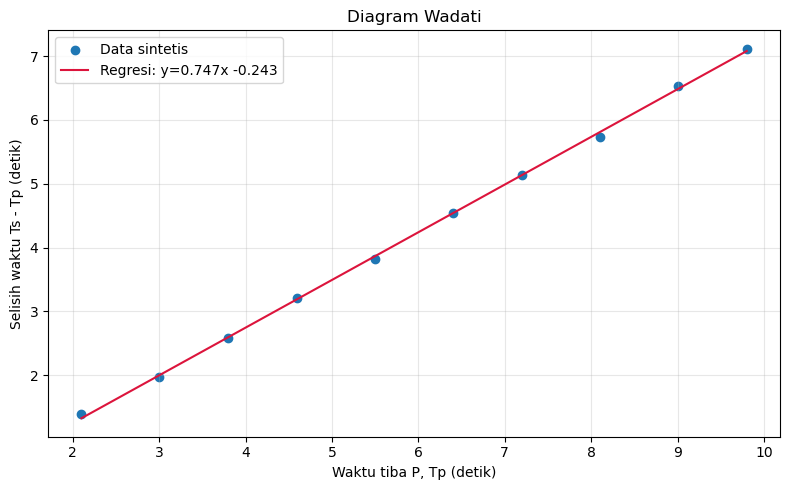

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Data sintetis: waktu tiba dalam detik
np.random.seed(7)
tp = np.array([2.1, 3.0, 3.8, 4.6, 5.5, 6.4, 7.2, 8.1, 9.0, 9.8])
vp_vs_true = 1.75
t0 = 0.35
ts_minus_tp = (vp_vs_true - 1) * (tp - t0) + np.random.normal(0, 0.045, len(tp))

# Regresi linear: (Ts-Tp) = slope * Tp + intercept
slope, intercept = np.polyfit(tp, ts_minus_tp, 1)
vp_vs = 1 + slope
# Rasio Poisson dari rasio Vp/Vs untuk medium elastik isotropik
poisson = (vp_vs**2 - 2) / (2 * (vp_vs**2 - 1))
fit = slope * tp + intercept

print('HASIL ANALISIS DIAGRAM WADATI (DATA SINTETIS)')
print(f'Jumlah pasangan waktu tiba : {len(tp)}')
print(f'Kemiringan regresi         : {slope:.3f}')
print(f'Intersep                   : {intercept:.3f} detik')
print(f'Estimasi Vp/Vs             : {vp_vs:.3f}')
print(f'Estimasi rasio Poisson     : {poisson:.3f}')

plt.figure(figsize=(8, 5))
plt.scatter(tp, ts_minus_tp, label='Data sintetis')
plt.plot(tp, fit, color='crimson', label=f'Regresi: y={slope:.3f}x {intercept:+.3f}')
plt.xlabel('Waktu tiba P, Tp (detik)')
plt.ylabel('Selisih waktu Ts - Tp (detik)')
plt.title('Diagram Wadati')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Contoh interpretasi dan verifikasi
Diagram memperlihatkan hubungan hampir linear antara waktu tiba P dan selisih waktu tiba S–P. Pada diagram Wadati sederhana, kemiringan regresi mendekati **Vp/Vs − 1**, sehingga rasio Vp/Vs dihitung sebagai **1 + kemiringan**. Rasio Poisson kemudian dihitung dengan asumsi medium elastik isotropik. Nilai akhir yang tampil di terminal mengikuti data sintetis dan gangguan acak yang ditambahkan kode. Interpretasi lapangan memerlukan pemeriksaan kualitas picking, geometri stasiun, serta kemungkinan heterogenitas kecepatan.

## PROMPT 2 — INTERPRETASI ANOMALI MAGNETIK DAN SINYAL ANALITIK

**Prompt R–T–C–I–K–O–Q–V**  
**R:** Bertindak sebagai ahli metode magnetik. **T:** Analisis profil anomali magnetik, hitung gradien horizontal dan amplitudo sinyal analitik sederhana. **C:** Tujuan latihan adalah mengenali batas sumber magnetik dari perubahan anomali. **I:** Gunakan profil jarak dan anomali magnetik sintetis dalam nT. **K:** Sinyal analitik 1D digunakan sebagai indikator perubahan lateral, bukan penentuan kedalaman yang unik. **O:** Buat grafik anomali dan amplitudo sinyal analitik serta ringkasan lokasi gradien terbesar. **Q:** Satuan nT dan m konsisten. **V:** Bandingkan lokasi puncak sinyal analitik dengan perubahan paling tajam pada anomali.

### Kode Python

HASIL ANALISIS MAGNETIK (DATA SINTETIS)
Jumlah titik profil             : 201
Anomali maksimum                : 118.04 nT
Anomali minimum                 : -12.87 nT
Gradien absolut terbesar        : 1.200 nT/m
Lokasi gradien terbesar         : 600.0 m
Puncak amplitudo sinyal analitik: 515.0 m


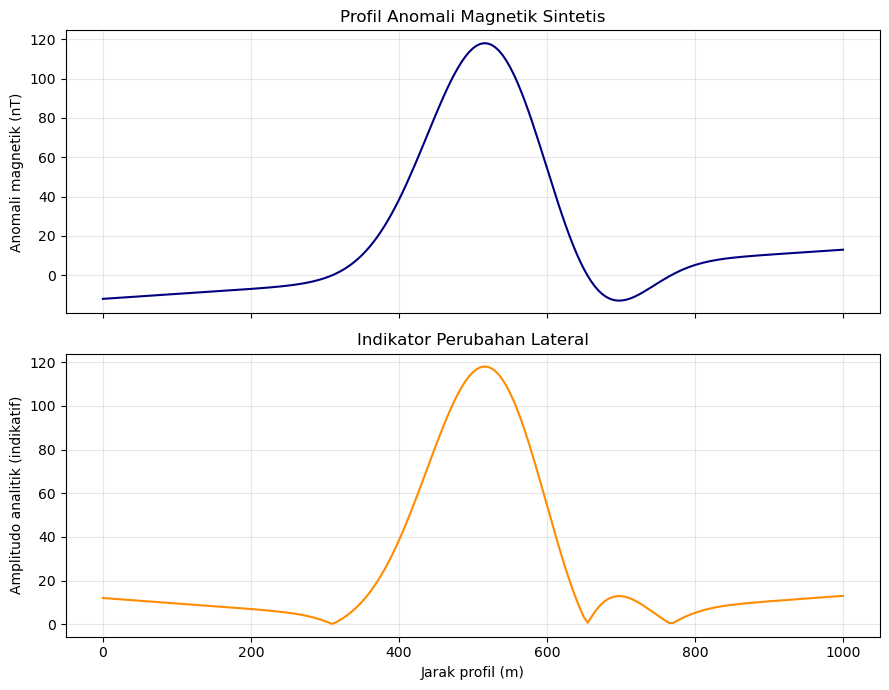

In [5]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 1000, 201)  # jarak dalam meter
# Anomali sintetis dari satu sumber lokal, ditambah tren regional kecil
anomaly = 120 * np.exp(-((x - 520) / 115)**2) - 35 * np.exp(-((x - 660) / 90)**2) + 0.025*x - 12
# Gradien horizontal dan amplitudo sinyal analitik 1D
spacing = x[1] - x[0]
gradient = np.gradient(anomaly, spacing)
analytic_amplitude = np.sqrt(anomaly**2 + gradient**2)
idx = np.argmax(np.abs(gradient))

print('HASIL ANALISIS MAGNETIK (DATA SINTETIS)')
print(f'Jumlah titik profil             : {len(x)}')
print(f'Anomali maksimum                : {anomaly.max():.2f} nT')
print(f'Anomali minimum                 : {anomaly.min():.2f} nT')
print(f'Gradien absolut terbesar        : {abs(gradient[idx]):.3f} nT/m')
print(f'Lokasi gradien terbesar         : {x[idx]:.1f} m')
print(f'Puncak amplitudo sinyal analitik: {x[np.argmax(analytic_amplitude)]:.1f} m')

fig, ax = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
ax[0].plot(x, anomaly, color='navy')
ax[0].set_ylabel('Anomali magnetik (nT)')
ax[0].set_title('Profil Anomali Magnetik Sintetis')
ax[0].grid(True, alpha=0.3)
ax[1].plot(x, analytic_amplitude, color='darkorange')
ax[1].set_xlabel('Jarak profil (m)')
ax[1].set_ylabel('Amplitudo analitik (indikatif)')
ax[1].set_title('Indikator Perubahan Lateral')
ax[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Contoh interpretasi dan verifikasi
Profil menunjukkan anomali lokal yang dibentuk secara matematis. Gradien horizontal yang besar menandai bagian profil dengan perubahan anomali paling cepat, sedangkan amplitudo analitik membantu menonjolkan perubahan tersebut. Posisi yang diperoleh kode merupakan indikator awal batas lateral sumber, bukan bukti tunggal batas geologi. Interpretasi yang lebih kuat perlu koreksi medan utama, koreksi variasi harian, informasi magnetisasi batuan, dan data lintasan tambahan.

## PROMPT 3 — INTERPRETASI DATA SEISMIK REFRAKSI

**Prompt R–T–C–I–K–O–Q–V**  
**R:** Bertindak sebagai geofisikawan dekat permukaan. **T:** Analisis kurva waktu tempuh terhadap jarak untuk mengidentifikasi dua kemiringan dan memperkirakan kecepatan lapisan serta kedalaman antarmuka menggunakan model dua lapis dengan lapisan bawah lebih cepat. **C:** Data sintetis mewakili survei seismik refraksi untuk investigasi dangkal. **I:** Gunakan jarak geofon dan waktu tempuh first arrival. **K:** Nyatakan asumsi lapisan horizontal, kecepatan konstan per lapisan, dan batas validitas model. **O:** Buat grafik waktu tempuh, garis model, hasil kecepatan dan kedalaman antarmuka. **Q:** Satuan m dan s konsisten. **V:** Pastikan kecepatan lapisan bawah lebih besar dan kedalaman positif.

### Kode Python

HASIL SEISMIK REFRAKSI (DATA SINTETIS)
Kecepatan lapisan atas, estimasi : 511.6 m/s
Kecepatan lapisan bawah, estimasi: 1508.2 m/s
Ketebalan lapisan atas, estimasi : 8.09 m
Catatan: estimasi sensitif terhadap pemilihan cabang dan noise.


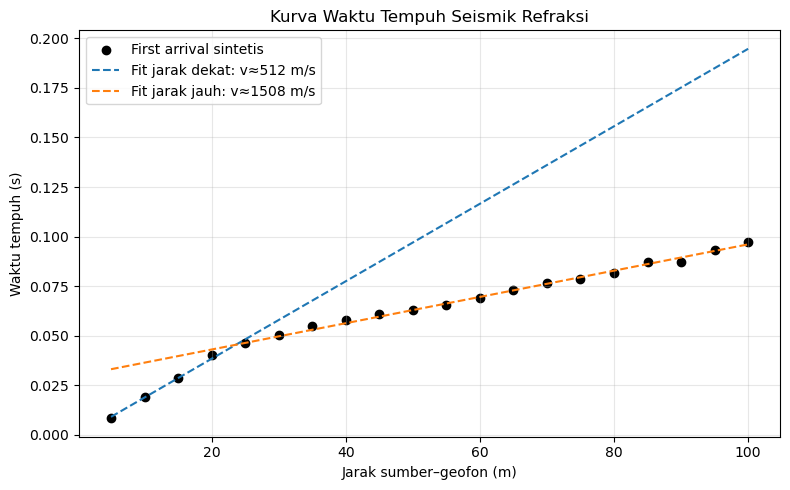

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Parameter model sintetis dua lapis
v1 = 500.0   # m/s, lapisan atas
v2 = 1500.0  # m/s, lapisan bawah
h_true = 8.0 # m, ketebalan lapisan atas
x = np.arange(5, 101, 5, dtype=float)
# Waktu gelombang langsung dan gelombang refraksi kritis
ti = h_true * np.sqrt(1/v1**2 - 1/v2**2) * 2
# Formula intercept-time untuk model dua lapis
t_direct = x / v1
t_head = x / v2 + ti
t_obs = np.minimum(t_direct, t_head) + np.random.default_rng(10).normal(0, 0.0015, len(x))

# Fit dua cabang secara demonstratif menggunakan rentang jarak awal/akhir
early = x <= 25
late = x >= 45
m1, b1 = np.polyfit(x[early], t_obs[early], 1)
m2, b2 = np.polyfit(x[late], t_obs[late], 1)
vel1_est = 1/m1
vel2_est = 1/m2
intercept_est = b2
h_est = max(0, intercept_est / (2*np.sqrt(1/vel1_est**2 - 1/vel2_est**2)))

print('HASIL SEISMIK REFRAKSI (DATA SINTETIS)')
print(f'Kecepatan lapisan atas, estimasi : {vel1_est:.1f} m/s')
print(f'Kecepatan lapisan bawah, estimasi: {vel2_est:.1f} m/s')
print(f'Ketebalan lapisan atas, estimasi : {h_est:.2f} m')
print('Catatan: estimasi sensitif terhadap pemilihan cabang dan noise.')

plt.figure(figsize=(8, 5))
plt.scatter(x, t_obs, label='First arrival sintetis', color='black')
xx = np.linspace(x.min(), x.max(), 200)
plt.plot(xx, m1*xx+b1, '--', label=f'Fit jarak dekat: v≈{vel1_est:.0f} m/s')
plt.plot(xx, m2*xx+b2, '--', label=f'Fit jarak jauh: v≈{vel2_est:.0f} m/s')
plt.xlabel('Jarak sumber–geofon (m)')
plt.ylabel('Waktu tempuh (s)')
plt.title('Kurva Waktu Tempuh Seismik Refraksi')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Contoh interpretasi dan verifikasi
Kurva waktu tempuh biasanya memiliki cabang jarak dekat yang didominasi gelombang langsung dan cabang jarak jauh yang dapat didominasi gelombang refraksi kritis. Kemiringan waktu terhadap jarak berhubungan dengan kebalikan kecepatan. Perhitungan kedalaman antarmuka dengan waktu intersep hanya berlaku pada model dua lapis sederhana dan sensitif terhadap pemilihan rentang regresi. Bila hasil kecepatan tidak meningkat ke lapisan bawah atau kedalaman menjadi tidak fisik, model asumsi dan picking perlu ditinjau kembali.

## PROMPT 4 — ESTIMASI GRADIEN GEOTERMAL DAN ALIRAN PANAS

**Prompt R–T–C–I–K–O–Q–V**  
**R:** Bertindak sebagai analis geofisika panas bumi. **T:** Fit hubungan suhu terhadap kedalaman, hitung gradien geotermal, lalu estimasi aliran panas konduktif dari konduktivitas termal. **C:** Contoh digunakan untuk latihan membaca data temperatur sumur. **I:** Gunakan data suhu sintetis pada beberapa kedalaman dan konduktivitas termal tetap. **K:** Anggap kondisi konduksi 1D tunak hanya untuk pendekatan; jangan menyimpulkan potensi produksi panas bumi dari gradien saja. **O:** Tampilkan grafik temperatur-kedalaman, regresi, gradien dalam °C/km dan aliran panas dalam mW/m². **Q:** Perhatikan arah sumbu kedalaman. **V:** Periksa satuan serta tanda gradien dan aliran panas.

### Kode Python

HASIL ANALISIS GEOTERMAL (DATA SINTETIS)
Jumlah titik temperatur : 9
Intersep temperatur     : 23.72 °C
Gradien geotermal       : 38.51 °C/km
Konduktivitas termal    : 2.20 W/(m K)
Estimasi aliran panas   : 84.7 mW/m²


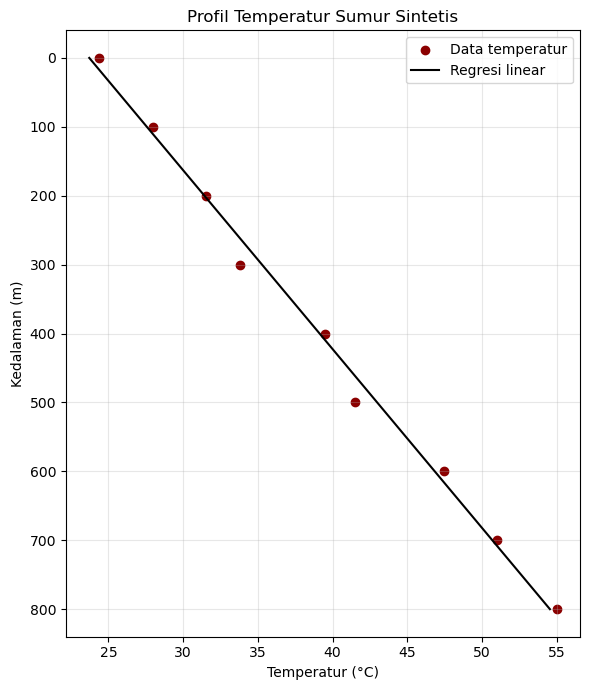

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Data suhu sintetis dari sumur
z = np.array([0, 100, 200, 300, 400, 500, 600, 700, 800], dtype=float)  # m
rng = np.random.default_rng(23)
T = 24 + 0.038*z + rng.normal(0, 0.7, len(z))  # °C
k = 2.2  # konduktivitas termal W/(m K), asumsi
slope, intercept = np.polyfit(z, T, 1)
gradient_C_km = slope * 1000
heat_flow_mW_m2 = k * slope * 1000  # W/m² ke mW/m²
T_fit = slope*z + intercept

print('HASIL ANALISIS GEOTERMAL (DATA SINTETIS)')
print(f'Jumlah titik temperatur : {len(z)}')
print(f'Intersep temperatur     : {intercept:.2f} °C')
print(f'Gradien geotermal       : {gradient_C_km:.2f} °C/km')
print(f'Konduktivitas termal    : {k:.2f} W/(m K)')
print(f'Estimasi aliran panas   : {heat_flow_mW_m2:.1f} mW/m²')

plt.figure(figsize=(6, 7))
plt.scatter(T, z, color='darkred', label='Data temperatur')
plt.plot(T_fit, z, color='black', label='Regresi linear')
plt.gca().invert_yaxis()
plt.xlabel('Temperatur (°C)')
plt.ylabel('Kedalaman (m)')
plt.title('Profil Temperatur Sumur Sintetis')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Contoh interpretasi dan verifikasi
Gradien geotermal diperoleh dari kemiringan regresi suhu terhadap kedalaman dan dinyatakan dalam °C/km. Dengan asumsi konduktivitas termal konstan, aliran panas konduktif diperkirakan dari hasil kali konduktivitas termal dan gradien suhu. Nilai ini adalah estimasi latihan; aliran fluida, perubahan litologi, kondisi sumur, dan variasi konduktivitas dapat membuat sistem nyata menyimpang dari model konduksi 1D.

## PROMPT 5 — ANALISIS PASANG SURUT DAN PEMISAHAN KOMPONEN PERIODIK

**Prompt R–T–C–I–K–O–Q–V**  
**R:** Bertindak sebagai analis deret waktu geofisika kelautan. **T:** Analisis tinggi muka air sintetis dan uraikan komponen periodik utama melalui regresi harmonik sederhana. **C:** Latihan ini menggambarkan pengamatan pasang surut dengan komponen semidiurnal dan diurnal. **I:** Gunakan waktu dalam jam dan tinggi muka air dalam meter. **K:** Model harmonik yang digunakan hanya memuat dua periode yang ditentukan, sehingga bukan analisis harmonik pasut lengkap. **O:** Tampilkan data, model fit, residual, amplitudo komponen, dan grafik. **Q:** Satuan dan periode dijelaskan. **V:** Bandingkan data dengan model serta hitung RMSE.

### Kode Python

HASIL ANALISIS PASANG SURUT (DATA SINTETIS)
Amplitudo komponen 12.42 jam: 0.648 m
Amplitudo komponen 24 jam   : 0.241 m
RMSE model                  : 0.062 m
Rentang tinggi air          : -0.93 hingga 0.96 m


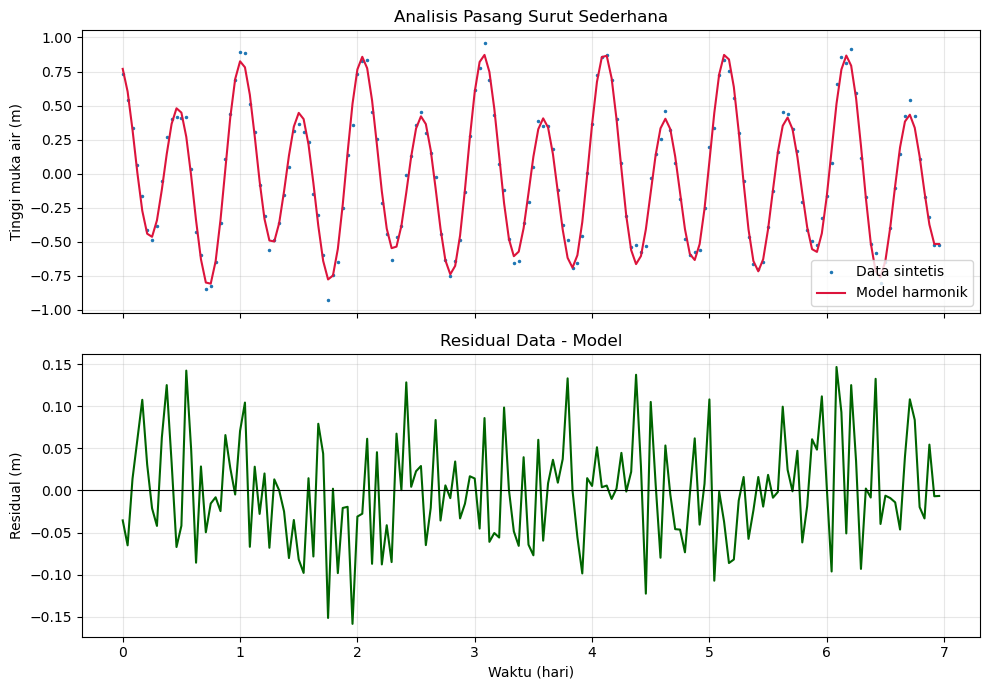

In [8]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(5)
t_hours = np.arange(0, 24*7, 1.0)
# Dua komponen contoh: periode 12.42 jam dan 24 jam
period_semidiurnal = 12.42
period_diurnal = 24.0
water_level = (0.65*np.cos(2*np.pi*t_hours/period_semidiurnal + 0.4)
               + 0.25*np.cos(2*np.pi*t_hours/period_diurnal - 0.7)
               + 0.03*np.sin(2*np.pi*t_hours/(24*3))
               + rng.normal(0, 0.07, len(t_hours)))

# Regresi harmonik: konstanta, sin/cos tiap frekuensi
w1 = 2*np.pi/period_semidiurnal
w2 = 2*np.pi/period_diurnal
G = np.column_stack([
    np.ones_like(t_hours), np.cos(w1*t_hours), np.sin(w1*t_hours),
    np.cos(w2*t_hours), np.sin(w2*t_hours)
])
coef, *_ = np.linalg.lstsq(G, water_level, rcond=None)
fit = G @ coef
residual = water_level - fit
amp1 = np.hypot(coef[1], coef[2])
amp2 = np.hypot(coef[3], coef[4])
rmse = np.sqrt(np.mean(residual**2))

print('HASIL ANALISIS PASANG SURUT (DATA SINTETIS)')
print(f'Amplitudo komponen 12.42 jam: {amp1:.3f} m')
print(f'Amplitudo komponen 24 jam   : {amp2:.3f} m')
print(f'RMSE model                  : {rmse:.3f} m')
print(f'Rentang tinggi air          : {water_level.min():.2f} hingga {water_level.max():.2f} m')

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
ax[0].plot(t_hours/24, water_level, '.', ms=3, label='Data sintetis')
ax[0].plot(t_hours/24, fit, color='crimson', lw=1.5, label='Model harmonik')
ax[0].set_ylabel('Tinggi muka air (m)')
ax[0].set_title('Analisis Pasang Surut Sederhana')
ax[0].grid(True, alpha=0.3)
ax[0].legend()
ax[1].plot(t_hours/24, residual, color='darkgreen')
ax[1].axhline(0, color='black', lw=0.8)
ax[1].set_xlabel('Waktu (hari)')
ax[1].set_ylabel('Residual (m)')
ax[1].set_title('Residual Data - Model')
ax[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Contoh interpretasi dan verifikasi
Regresi harmonik memodelkan tinggi muka air sebagai kombinasi dua komponen periodik yang ditentukan. Amplitudo masing-masing komponen dihitung dari koefisien sinus dan kosinusnya. RMSE merangkum besar residual model, tetapi residual masih dapat memuat komponen pasut lain, variasi meteorologis, dan noise. Untuk analisis pasut nyata, diperlukan rentang pengamatan yang memadai dan lebih banyak konstituen harmonik.

---

## Kesimpulan
Lima studi kasus alternatif memperlihatkan bagaimana kerangka R–T–C–I–K–O–Q–V dapat diterapkan pada masalah geofisika yang berbeda: seismologi (Wadati dan refraksi), metode magnetik, geotermal, serta deret waktu kelautan. Setiap kode dirancang untuk dijalankan sebagai sel terpisah di Jupyter Notebook atau dipindahkan ke VS Code sebagai file Python. Data sintetis memudahkan latihan, tetapi interpretasi data lapangan membutuhkan kontrol kualitas, metadata, dan verifikasi asumsi fisik.